In [1]:
import numpy as np
from qutip import *
import matplotlib.pyplot as plt
from fluxonium_classes import *

### Constants and unit conversion

In [2]:
e = 1.602*10**(-19)
h = 6.626*10**(-34)
phi_0 = h/(2*e)
unit_fF_inv_to_GHz = e**2 /h * 10**6
unit_nH_inv_to_GHz = 1/h * (phi_0/(2*np.pi))**2

### Plot wavefunctions

In [3]:
def Ecs_from_caps_qi(CJ1, CJ2, C_shunt):

    C_tot = CJ1 + CJ2

    E_cq = 1/2/(CJ1*(CJ2)/C_tot+C_shunt) * unit_fF_inv_to_GHz

    E_ci = 1/(2*C_tot) * unit_fF_inv_to_GHz

    return E_cq, E_ci

In [4]:
# all in GHz
E_L = 0.132
E_L = 1
C_J1 = 30 #fF
C_J2 = 30 #fF
C = 65 #fF, want to satisfy E_Cq = 0.479 GHz
E_J1 = 3.395 # GHz, want to satisfy E_Jq=3.395
E_J2 = 3.395
E_J1 = 10
E_J2 = 10


N_wavfuncs = 5
ext_phase = np.pi

dflux1 = Double_Junc_Fluxonium(E_J1, E_J2, C_J1, C_J2, C, E_L, delta_phi = 0.05,
                   nbr_periods = 3)

#dflux1.plot_wavefuncs(N_wavfuncs, 0)

In [5]:
E_cq, E_ci = Ecs_from_caps_qi(C_J1, C_J2, C)
print(E_cq, E_ci)

0.2420770449743435 0.3227693932991247


In [6]:
vals, vecs = dflux1.eigenstates_symm(E_cq, E_ci, np.pi, N_levels=10)
#vals, vecs = dflux1.eigenstates_symm(0.2, 1, ext_phase, N_levels=10)
print("energies [GHz]:")
print(vals)

print("transitions [GHz]:")
print(np.diff(vals))

energies [GHz]:
[-10.85752476 -10.85749172  -7.71279853  -7.71190271  -4.65075731
  -4.64010396  -4.35926292  -4.35755654  -1.70921773  -1.63666957
  -1.60906818  -1.57024559   0.83504063   0.99167889   1.15658781]
transitions [GHz]:
[3.30388784e-05 3.14469319e+00 8.95820565e-04 3.06114539e+00
 1.06533551e-02 2.80841037e-01 1.70637962e-03 2.64833881e+00
 7.25481590e-02 2.76013887e-02 3.88225944e-02 2.40528621e+00
 1.56638267e-01 1.64908917e-01]


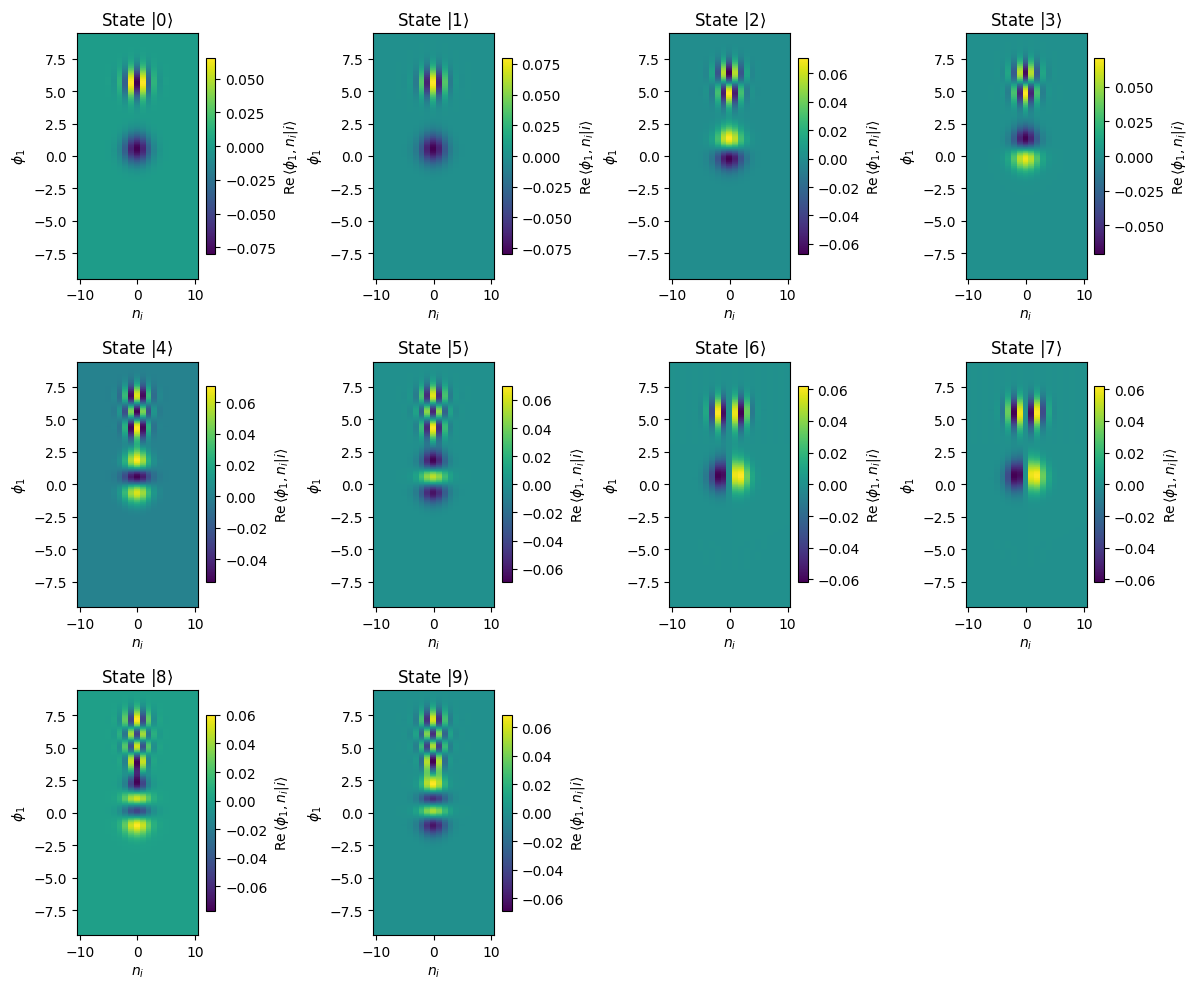

In [7]:
dflux1.plot_wavefuncs_symm(E_cq, E_ci, 10, ext_phase)

In [7]:
print("EC1 =", dflux1.E_C1)
print("EC2 =", dflux1.E_C2)
print("g12 =", dflux1.g_12)

vals, vecs = dflux1.eigenstates(0, N_levels=10)

print("energies [GHz]:")
print(vals)

print("transitions [GHz]:")
print(np.diff(vals))

print("transitions [MHz]:")
print(np.diff(vals)*1000)

EC1 = 4.965682973832687
EC2 = 4.965682973832687
g12 = 37.73919060112842
energies [GHz]:
[2.19410566 2.20903257 2.23008586 2.30939088 2.31109702 2.4636807
 2.52788752 2.611028   2.70676952 2.82024161 2.94131477 3.07440802
 3.21883874 3.37254677 3.54368352]
transitions [GHz]:
[0.01492691 0.02105329 0.07930502 0.00170614 0.15258368 0.06420682
 0.08314048 0.09574152 0.1134721  0.12107316 0.13309325 0.14443071
 0.15370803 0.17113675]
transitions [MHz]:
[ 14.92690921  21.05328563  79.30501869   1.70614432 152.58367934
  64.20682389  83.14047583  95.7415174  113.472098   121.07315675
 133.09325076 144.4307149  153.70803254 171.13675315]


### Transition frequencies from ground state

In [19]:
vals, vecs = dflux1.eigenstates(np.pi, 6)

In [22]:
print(vals[9]-vals[0])

1.906473641934987


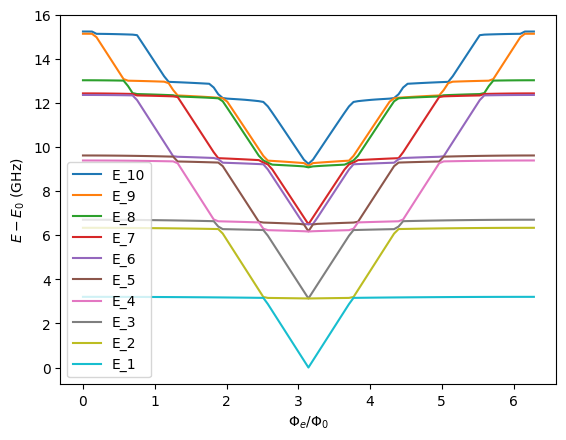

In [17]:

N_en_levels = 11
N_flux = 101
ext_phase = np.linspace(0, 2*np.pi, N_flux)
#ext_phase = np.linspace(2*np.pi - 0.25, 2*np.pi + 0.25, 9)
dflux1.plot_transitions_over_flux_symm(E_cq, E_ci,ext_phase, N_en_levels)
plt.legend()

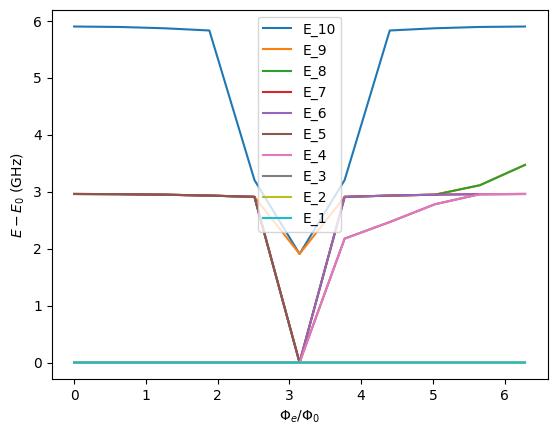

In [18]:
N_en_levels = 11
N_flux = 11
ext_phase = np.linspace(0, 2*np.pi, N_flux)
#ext_phase = np.linspace(2*np.pi - 0.25, 2*np.pi + 0.25, 9)
dflux1.plot_transitions_over_flux(ext_phase, N_en_levels)
plt.legend()

In [45]:
resonator_list = []
cap_mat_list = []

#gammas = np.linspace(0.5, 1.5, 5)
gammas = [1]
Cr = 300 #fF
Lr = 5 #nH
fock_dim = 4

Cg = 0 # fF
C_J = C_J1

N_flux = 11
ext_phase = np.linspace(np.pi - 0.25, np.pi + 0.25, N_flux)

for gamma in gammas:
    res = Resonator(Lr, Cr, fock_dim)
    resonator_list.append(res)

    cap_mat = np.matrix([

                [C+C_J + Cg/2, C, -Cg/2],

                [C, C+C_J + Cg/2, Cg/2],

                [-Cg/2, Cg/2, Cg + Cr]

            ])
    
    cap_mat_list.append(cap_mat)

E_Cr, E_C1, E_C2, g1r, g2r, g12= dflux1.add_resonator_coupling(resonator_list, cap_mat_list)
print(E_Cr, E_C1, E_C2, g1r, g2r, g12)

res1 = resonator_list[0]

0.06455387865982494 0.4997719638179995 0.4997719638179995 0.0 0.0 -3.748289728634996


In [7]:
print(dflux1.E_C1, dflux1.E_C2, dflux1.g_12)

1.3256600081928336 1.3256600081928336 -8.760883532404813


In [ ]:
k = (C_1 - C_2) / (C_1 + C_2)

C_matrix_protected_qi = cap_mat = np.matrix([

                [C+C_1+C_2+Cg*(C_1**2 + C_2**2)/(C_1 + C_2)**2 , C_1 - C_2, -k*Cg],

                [C_1 - C_2,  C_1 + C_2 + 2 * Cg, 2*Cg],

                [-k*Cg, 2*Cg, 2*Cg + Cr]

            ])

0 0.0 2.5008967520844546e-07 0.0003465825867914753
1 0.0022283073846092183 0.0003469613185712116 8.61088001344713e-07
2 0.004606107958681438 2.008765248836693e-07 0.0004254966604262301
3 0.006069895175032758 7.205805901539134e-05 7.803969661052979e-07
4 0.5788825239774208 1.2511299529857526e-06 0.003486038265554718
5 0.6080189875707483 0.0033350958985972944 1.6210187511256985e-05
6 0.64966117807692 6.2015632030672126e-06 0.018014697242216243
7 0.6890445331969649 0.018401708606081722 7.051819478657782e-06
8 0.892272376619666 1.0541416899720808e-06 0.003482019574979507
9 0.9600610392268564 0.004186700445976287 2.484853148836845e-06
10 1.041017067606845 1.846093650815596e-06 0.005543222473557687
11 1.1277474578193152 3.326301451615924e-05 7.015639999559392e-06
12 1.223233917871648 1.0362040081752169e-06 0.00011024349243719204
13 1.3521486786568455 0.00010085641847202835 8.577164738026485e-07
14 1.4669762579354475 3.964829114284631e-07 0.0007734070903302945
15 1.603076929832305 0.000440458

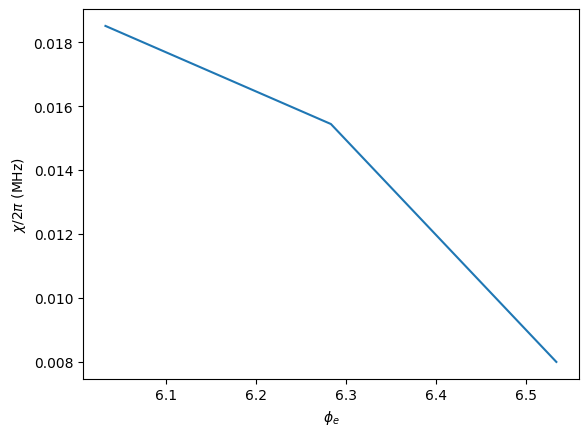

In [8]:
ext_phase = np.linspace(-2*np.pi, 2*np.pi, 9)
ext_phase = np.linspace(2*np.pi - 0.25, 2*np.pi + 0.25, 3)
#ext_phase = [2*np.pi]
res_ind = 0
truncation_level = 6
N_red = 120

#chis_sw = dflux1.find_chi_over_flux_SW(res_ind, truncation_level, ext_phase)
chis_full = dflux1.find_chi_full_over_flux_reduced(res_ind, N_red, ext_phase)

In [73]:
chiss, frs, fqs = chis_full
print(chiss)

[np.float64(4.3856689593644855), np.float64(-20.925230013381174), np.float64(3.2249870769048283), np.float64(1.9165637619630582), np.float64(4.822569527011961), np.float64(-4.190034962841816), np.float64(1.309352365932992), np.float64(-10.251398253449146), np.float64(-3.837240690913901)]


In [40]:
import json
chis, frs, fqs = chis_full

filename = "chi_convergence.json"

try:
    with open(filename, "r") as f:
        results = json.load(f)
except FileNotFoundError:
    results = {}

results[str(N_red)] = {
    "chis": chis,
    "frs": frs,
    "fqs": fqs
}

with open(filename, "w") as f:
    json.dump(results, f, indent=2)

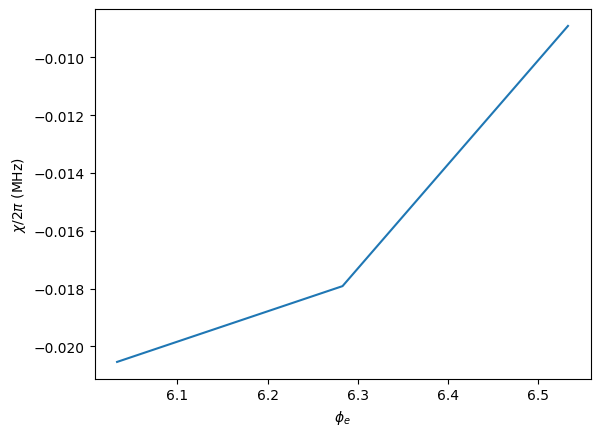

In [9]:
ext_phase = np.linspace(2*np.pi - 0.25, 2*np.pi + 0.25, 3)
truncation_level = 70
chis_sw = dflux1.find_chi_over_flux_SW(res_ind, truncation_level, ext_phase)

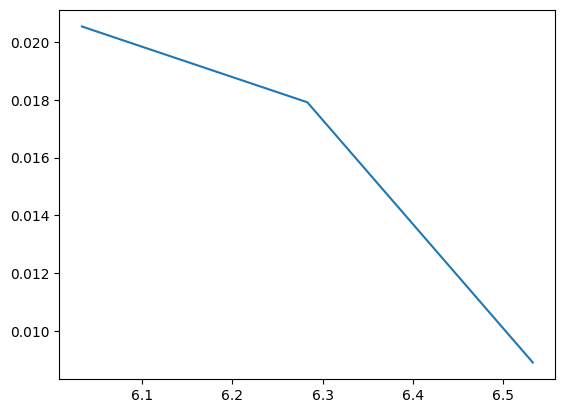

In [13]:
plt.plot(ext_phase, [-c for c in chis_sw])

In [75]:
print(chis_sw)

[np.float64(-5.400471165027476), np.float64(-63.053607244131946), np.float64(-8.17878272172868), np.float64(-5.018989760426977), np.float64(-4.373481361848899), np.float64(-1.1698936520186272), np.float64(-6.336424050477929), np.float64(243.434083216736), np.float64(-3.9679384269384625)]


In [69]:
import json
chis = chis_sw

filename = "chi_convergence_SW.json"

try:
    with open(filename, "r") as f:
        results = json.load(f)
except FileNotFoundError:
    results = {}

results[str(truncation_level)] = {
    "chis": chis
}

with open(filename, "w") as f:
    json.dump(results, f, indent=2)